# LangFont: Language-Guided Few-Shot Font Generation

**Idea.** Given only a few reference glyphs of an unseen font (1/3/5/10 images) **and** a short text description
(e.g. *"bold, rounded, handwritten"*), generate any missing character in that font.

**Method.**
- A pretrained **Stable Diffusion v1.5** UNet is fine-tuned with **LoRA (PEFT)**.
- Reference glyphs are turned into extra "style tokens" by a small trainable **StyleEncoder**
  (frozen **CLIP** image embeddings + a light CNN). These tokens are appended to the CLIP text tokens,
  so the UNet cross-attention sees *text + images* together.
- **Modality dropout** during training lets one model run in three modes: image-only, text-only, image+text.
- A **conditional VAE (CVAE)** few-shot baseline (same idea as the MS thesis model) is trained for comparison.

**Data.** Google Fonts (downloaded sparsely from GitHub), text descriptions built automatically from
font metadata + **OpenCV** shape analysis. Omniglot / EMNIST are used only for a sanity check.

**Ablations.** (1) image-only vs text-only vs both, (2) number of reference images K = 1 / 3 / 5 / 10,
(3) LangFont vs CVAE baseline.

**Metrics.** FID (+ KID, more stable for small sets), SSIM, CLIP score (text-image, CLIP-T) and
CLIP image similarity to ground truth (CLIP-I).



## 1. Install dependencies

In [1]:
# ---- Install dependencies (run once per runtime) ----
import subprocess, sys, importlib.util  # subprocess runs pip, sys points to this Python, importlib checks packages

# All packages this project needs
PACKAGES = [
    "diffusers==0.29.0",       # Fixed version to bypass torchao import conflict
    "torchao>=0.16.0",         # Upgrade torchao to satisfy PEFT requirements
    "transformers>=4.44.0",    # CLIP text and image encoders
    "peft>=0.12.0",            # LoRA adapters
    "accelerate>=0.33.0",      # faster / lower-memory model loading
    "bitsandbytes",            # 8-bit AdamW optimizer (saves optimizer memory)
    "torchmetrics[image]>=1.4",# FID, KID metrics
    "torch-fidelity",          # Inception backbone used by torchmetrics FID/KID
    "scikit-image",            # SSIM
    "fonttools",               # check which characters a font file contains
    "ftfy",                    # text cleaning used by the CLIP tokenizer
    "pandas", "matplotlib", "tqdm",  # tables, plots, progress bars
]
# Install quietly with the interpreter that runs this notebook
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PACKAGES], check=True)
# OpenCV is usually preinstalled (Colab/Kaggle); install the headless build only if it is missing
if importlib.util.find_spec("cv2") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"], check=True)
# Remind the user about a possible restart after upgrading libraries
print("Done. If the next cell fails on an import, restart the runtime once and continue.")

Done. If the next cell fails on an import, restart the runtime once and continue.


## 2. Storage: Google Drive for everything that must survive a disconnect
Free Colab GPUs stop without warning. Checkpoints, the data cache, generations and results are saved in
**Google Drive**, so when you get GPU time again you just run all cells and training continues from the last save.
Heavy reads (the memory-mapped cache) still happen on the fast local disk; the cache is copied to/from Drive.

In [2]:
import os                      # environment variables
import shutil                  # file copying
from pathlib import Path       # clean path handling

USE_DRIVE = True               # False = keep everything on the local disk only
DRIVE_FOLDER = "LangFont"      # folder created inside "My Drive"
HF_CACHE_ON_DRIVE = False      # True = also keep downloaded SD/CLIP models (~4 GB) on Drive to skip re-downloads

IN_COLAB = False               # detect Google Colab
try:
    from google.colab import drive   # only exists on Colab
    IN_COLAB = True
except ImportError:
    pass

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")                                  # asks for permission the first time
    PERSIST_DIR = Path("/content/drive/MyDrive") / DRIVE_FOLDER    # survives runtime resets
elif Path("/kaggle/working").exists():
    PERSIST_DIR = Path("/kaggle/working/langfont_persist")         # Kaggle: kept when you "Save Version"
else:
    PERSIST_DIR = Path("./langfont_persist")                       # local machine
PERSIST_DIR.mkdir(parents=True, exist_ok=True)                     # create the folder if missing

LOCAL_DIR = Path("/content/langfont_work") if IN_COLAB else Path("./langfont_work")  # fast temporary disk
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

if HF_CACHE_ON_DRIVE:
    os.environ["HF_HOME"] = str(PERSIST_DIR / "hf_cache")          # must be set before transformers is imported

print("persistent folder:", PERSIST_DIR)                          # where weights will be saved
print("local work folder:", LOCAL_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
persistent folder: /content/drive/MyDrive/LangFont
local work folder: /content/langfont_work


## 3. Imports and memory-friendly environment

In [3]:
import os  # environment variables and file system helpers
# Let the CUDA allocator grow segments instead of fragmenting memory (must be set before torch is imported)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Silence tokenizer fork warnings inside DataLoader workers
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc, json, math, random, re, shutil, string, subprocess, time  # standard library utilities
from pathlib import Path                           # clean path handling

import numpy as np                                 # arrays and memory-mapped files
import cv2                                         # OpenCV: resizing, contours, corner detection
import pandas as pd                                # result tables
import matplotlib.pyplot as plt                    # plots and image grids
from tqdm.auto import tqdm                         # progress bars
from PIL import Image, ImageDraw, ImageFont        # font rendering
from fontTools.ttLib import TTFont                 # read a font's character map

import torch                                       # deep learning framework
import torch.nn as nn                              # neural network layers
import torch.nn.functional as F                    # functional ops (interpolate, losses)
from torch.utils.data import Dataset, DataLoader   # data pipeline

from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, DPMSolverMultistepScheduler  # SD parts
from diffusers.optimization import get_scheduler                   # learning-rate schedules
from diffusers.training_utils import compute_snr, cast_training_params  # Min-SNR weighting, fp32 casting of LoRA
from transformers import (CLIPTokenizer, CLIPTextModel,             # SD text encoder
                          CLIPVisionModelWithProjection,            # CLIP image encoder (embeddings)
                          CLIPTextModelWithProjection)              # CLIP text encoder for CLIP score
from peft import LoraConfig                                         # LoRA configuration
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict  # save / load only LoRA weights
from skimage.metrics import structural_similarity                   # SSIM metric
from torchmetrics.image.fid import FrechetInceptionDistance         # FID metric
from torchmetrics.image.kid import KernelInceptionDistance          # KID metric

print("torch", torch.__version__)  # show versions for reproducibility

/usr/local/lib/python3.13/dist-packages/diffusers/models/transformers/transformer_2d.py:34: FutureWarning: `Transformer2DModelOutput` is deprecated and will be removed in version 1.0.0. Importing `Transformer2DModelOutput` from `diffusers.models.transformer_2d` is deprecated and this will be removed in a future version. Please use `from diffusers.models.modeling_outputs import Transformer2DModelOutput`, instead.
  deprecate("Transformer2DModelOutput", "1.0.0", deprecation_message)


torch 2.11.0+cu130


## 4. Configuration (auto-adjusts to your GPU)

In [4]:
# ---- Hardware ----
assert torch.cuda.is_available(), "A CUDA GPU is required (Colab: Runtime > Change runtime type > GPU)."
DEVICE = torch.device("cuda")                                    # all models run on the GPU
_props = torch.cuda.get_device_properties(0)                     # GPU properties
VRAM_GB = _props.total_memory / 1024 ** 3                        # total GPU memory in GB
USE_BF16 = _props.major >= 8                                     # bf16 only on Ampere or newer (A100, RTX 30xx+)
WEIGHT_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16     # half precision for frozen weights
torch.backends.cuda.matmul.allow_tf32 = True                     # faster matmuls on Ampere
torch.backends.cudnn.allow_tf32 = True                           # faster convolutions on Ampere
torch.backends.cudnn.benchmark = True                            # pick fastest conv kernels for fixed shapes

# ---- Quick test switch ----
FAST_DEV_RUN = False   # True = tiny run (few fonts, few steps) to check that every cell works end to end
if FAST_DEV_RUN and PERSIST_DIR.name != "fast_test":   # guard: re-running this cell must not nest folders
    PERSIST_DIR = PERSIST_DIR / "fast_test"  # test run saves separately, so it never mixes with the real training
    PERSIST_DIR.mkdir(parents=True, exist_ok=True)

# ---- Paths and model ids ----
WORK_DIR = LOCAL_DIR                                   # fast local disk: font downloads and the working cache
SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # pretrained Stable Diffusion 1.5
CLIP_MODEL_ID = "openai/clip-vit-large-patch14"        # CLIP ViT-L/14 (same family as SD's text encoder)
CLIP_DIM = 768                                         # CLIP ViT-L/14 projection size
CTX_DIM = 768                                          # SD 1.5 cross-attention context size

# ---- Characters ----
CHARSET = string.ascii_uppercase + string.ascii_lowercase + string.digits  # 62 characters
N_CHARS = len(CHARSET)                                 # 62
CHAR2IDX = {c: i for i, c in enumerate(CHARSET)}       # char -> index

# ---- Dataset size ----
MAX_FONT_FILES = 40 if FAST_DEV_RUN else 300           # number of font files kept after filtering
MAX_FILES_PER_FAMILY = 2                               # at most 2 styles per family (more diversity)
N_TEST_FAMILIES = 6 if FAST_DEV_RUN else 30            # unseen families held out for evaluation

# ---- Resolutions ----
if VRAM_GB < 13:          # e.g. 8-12 GB cards
    RES, TRAIN_BATCH, GRAD_ACCUM, GEN_BATCH = 256, 4, 4, 4
elif VRAM_GB < 20:        # e.g. T4 / P100 (15-16 GB)
    RES, TRAIN_BATCH, GRAD_ACCUM, GEN_BATCH = 256, 8, 2, 8
elif VRAM_GB < 40:        # e.g. A10 / L4 / RTX 3090/4090
    RES, TRAIN_BATCH, GRAD_ACCUM, GEN_BATCH = 512, 4, 4, 8
else:                     # A100 / H100
    RES, TRAIN_BATCH, GRAD_ACCUM, GEN_BATCH = 512, 8, 2, 16
RUN_CONFIG = PERSIST_DIR / "run_config.json"   # remembers the resolution of the first session
if RUN_CONFIG.exists():
    _saved_res = json.loads(RUN_CONFIG.read_text())["RES"]          # resolution used when training started
    if _saved_res != RES:
        print(f"Different GPU this session; keeping RES={_saved_res} so the saved cache and weights still match.")
    RES = _saved_res                                                # never change resolution mid-training
else:
    RUN_CONFIG.write_text(json.dumps({"RES": RES}))                 # first session: lock the resolution
STORE_RES = 128           # glyph pixels stored on disk at 128 px (CVAE, metrics, descriptors)
REF_RES = 64              # reference glyph size fed to the small CNN in the StyleEncoder
EVAL_RES = 128            # all methods are compared at 128 px grayscale
CACHE_BATCH = 16          # VAE encode batch size while building the cache

# ---- Few-shot and model settings ----
MAX_K = 10                        # max number of reference glyphs
K_TRAIN_CHOICES = [1, 3, 5, 10]   # K is sampled from this list during training
K_EVAL = [1, 3, 5, 10]            # K ablation values
K_MODALITY = 5                    # K used for the image/text/both ablation
N_TOK_CLIP = 4                    # style tokens per reference from CLIP embedding
N_TOK_CNN = 4                     # style tokens per reference from the CNN
LORA_RANK = 8                     # LoRA rank (small = less memory)

# ---- LangFont training ----
MAX_TRAIN_STEPS = 150 if FAST_DEV_RUN else 4000   # optimizer steps
LEARNING_RATE = 1e-4                              # LR for LoRA + StyleEncoder
LR_WARMUP = 20 if FAST_DEV_RUN else 200           # warm-up steps
SAVE_EVERY = 50 if FAST_DEV_RUN else 200          # save to Drive every N optimizer steps
SAVE_EVERY_MIN = 10                               # ...and also at least every N minutes (free GPUs stop suddenly)
LOG_EVERY = 10 if FAST_DEV_RUN else 50            # logging frequency
MIN_SNR_GAMMA = 5.0                               # Min-SNR loss weighting (faster, stabler convergence)
P_UNCOND = 0.10                                   # drop everything -> learns unconditional branch for CFG
P_TEXT_ONLY = 0.15                                # drop references -> learns text-only mode
P_IMAGE_ONLY = 0.15                               # drop style words -> learns image-only mode
NUM_WORKERS = min(2, os.cpu_count() or 1)         # few workers = low CPU RAM

# ---- Inference ----
INFER_STEPS = 10 if FAST_DEV_RUN else 25          # DPM-Solver steps
GUIDANCE = 5.0                                    # classifier-free guidance scale

# ---- Evaluation ----
TARGET_CHARS = "AGRaegks37"                       # fixed characters to generate for every test font
N_TARGETS_PER_FONT = 4 if FAST_DEV_RUN else 10    # how many of them to use

# ---- CVAE baseline ----
CVAE_RES = 128                                    # CVAE works at 128 px
CVAE_Z = 128                                      # latent size
CVAE_STEPS = 200 if FAST_DEV_RUN else 6000        # training steps
CVAE_BATCH = 32 if VRAM_GB < 13 else 64           # batch size
CVAE_LR = 2e-4                                    # learning rate
CVAE_BETA = 1.0                                   # final KL weight
CVAE_KL_WARMUP = 50 if FAST_DEV_RUN else 2000     # KL annealing steps
CVAE_CHECKPOINT = None   # put the path to your thesis CVAE weights here if the architecture matches

SEED = 42                                          # global seed

# ---- Where things are saved ----
CACHE_NAME = f"cache_res{RES}_n{MAX_FONT_FILES}"         # one cache per setting
CACHE_DIR = WORK_DIR / CACHE_NAME                         # local copy (fast memory-mapped reads)
DRIVE_CACHE_DIR = PERSIST_DIR / CACHE_NAME                # Drive copy (survives disconnects)
CACHE_FILES = ["glyphs.npy", "latents.npy", "clip.npy", "meta.json", "geometry.npy"]  # files in the cache
CKPT = PERSIST_DIR / "langfont_ckpt.pt"                   # full LangFont training state (resume)
FINAL_WEIGHTS = PERSIST_DIR / "langfont_final_weights.pt" # LoRA + StyleEncoder only, fp16 (for inference/sharing)
CVAE_CKPT = PERSIST_DIR / "cvae_ckpt.pt"                  # full CVAE training state (resume)
CVAE_FINAL = PERSIST_DIR / "cvae_final_weights.pt"        # CVAE weights only
GEN_DIR = PERSIST_DIR / "generations"                     # generated evaluation images
GEN_DIR.mkdir(exist_ok=True)

# Print the chosen setup
print(f"GPU: {_props.name} | VRAM {VRAM_GB:.1f} GB | dtype {WEIGHT_DTYPE} | RES {RES} | "
      f"batch {TRAIN_BATCH} x accum {GRAD_ACCUM} | fast={FAST_DEV_RUN}")

GPU: Tesla T4 | VRAM 14.6 GB | dtype torch.float16 | RES 256 | batch 8 x accum 2 | fast=False


## 5. Utilities and shared helpers

In [5]:
def seed_everything(seed: int):
    random.seed(seed)                      # Python RNG
    np.random.seed(seed)                   # NumPy RNG
    torch.manual_seed(seed)                # CPU torch RNG
    torch.cuda.manual_seed_all(seed)       # GPU torch RNG

def free_memory():
    gc.collect()                           # free Python objects without references
    torch.cuda.empty_cache()               # return cached GPU blocks to the driver

def safe_save(obj, path: Path):
    # write to a temp file first, keep the previous save as .bak, then swap; a cut-off write never destroys a good file
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")              # temporary file in the same folder
    bak = path.with_name(path.name + ".bak")              # previous good checkpoint
    torch.save(obj, tmp)                                  # slow part (upload to Drive) happens on the temp file
    if path.exists():
        os.replace(path, bak)                             # keep the older save as a backup
    os.replace(tmp, path)                                 # new save becomes the main file

def safe_load(path: Path):
    # try the main checkpoint, then the backup if the main one is missing or broken
    path = Path(path)
    for p in (path, path.with_name(path.name + ".bak")):
        if p.exists():
            try:
                return torch.load(p, map_location="cpu", weights_only=False)
            except Exception as e:
                print(f"could not read {p.name} ({e}); trying backup")
    return None                                           # nothing saved yet

def copy_file(src: Path, dst: Path):
    # copy through a temp name so a half-copied file is never mistaken for a complete one
    dst.parent.mkdir(parents=True, exist_ok=True)
    tmp = dst.with_name(dst.name + ".part")
    shutil.copyfile(src, tmp)
    os.replace(tmp, dst)

def restore_cache_from_drive():
    # new session: copy the cache from Drive to the fast local disk (much faster than rebuilding it)
    if (CACHE_DIR / "meta.json").exists() or not (DRIVE_CACHE_DIR / "meta.json").exists():
        return
    for name in CACHE_FILES:
        if (DRIVE_CACHE_DIR / name).exists():
            print("restoring", name, "from Drive")
            copy_file(DRIVE_CACHE_DIR / name, CACHE_DIR / name)

def backup_to_drive(*names):
    # copy finished cache files to Drive (skipped when Drive is not used)
    if DRIVE_CACHE_DIR.resolve() == CACHE_DIR.resolve():
        return
    for name in names:
        if (CACHE_DIR / name).exists():
            copy_file(CACHE_DIR / name, DRIVE_CACHE_DIR / name)

def file_mb(path) -> str:
    return f"{Path(path).stat().st_size / 1024**2:.1f} MB" if Path(path).exists() else "missing"

def gpu_mem(tag: str = ""):
    alloc = torch.cuda.memory_allocated() / 1024 ** 3     # memory used by live tensors
    reserved = torch.cuda.memory_reserved() / 1024 ** 3   # memory held by the allocator
    print(f"[GPU {tag}] allocated {alloc:.2f} GB | reserved {reserved:.2f} GB")

def char_phrase(c: str) -> str:
    # CLIP's tokenizer lower-cases text, so case must be spelled out in words
    if c.isupper():
        return f"uppercase letter {c.lower()}"
    if c.islower():
        return f"lowercase letter {c}"
    return f"digit {c}"

def build_prompt(c: str, style: str = None) -> str:
    base = f"a black glyph of the {char_phrase(c)} on a white background"  # content part
    return f"{base}, {style} font" if style else base                     # optional style words

def to_ref_res(glyphs: np.ndarray) -> np.ndarray:
    # resize a stack of 128 px glyphs [K,H,W] to REF_RES for the CNN; INTER_AREA keeps thin strokes
    return np.stack([cv2.resize(g, (REF_RES, REF_RES), interpolation=cv2.INTER_AREA) for g in glyphs])

def load_sd_part(cls, subfolder, **kw):
    # try the half-precision files first (half the download and disk), fall back to full files
    try:
        return cls.from_pretrained(SD_MODEL_ID, subfolder=subfolder, variant="fp16", **kw)
    except Exception:
        return cls.from_pretrained(SD_MODEL_ID, subfolder=subfolder, **kw)

def load_vae():
    vae = load_sd_part(AutoencoderKL, "vae", torch_dtype=WEIGHT_DTYPE)  # SD VAE in half precision
    vae = vae.to(DEVICE).eval()                                         # move to GPU, inference mode
    vae.requires_grad_(False)                                           # never trained
    try:
        vae.enable_slicing()                                            # decode one image at a time
    except Exception:
        pass
    return vae

def load_clip_vision():
    m = CLIPVisionModelWithProjection.from_pretrained(CLIP_MODEL_ID, torch_dtype=WEIGHT_DTYPE)  # image tower only
    return m.to(DEVICE).eval().requires_grad_(False)                                          # frozen on GPU

CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1)  # CLIP normalisation mean
CLIP_STD = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1)  # CLIP normalisation std

def clip_preprocess(gray_uint8: torch.Tensor) -> torch.Tensor:
    x = gray_uint8.float().div(255.0).unsqueeze(1)                       # [B,1,H,W] in [0,1]
    x = F.interpolate(x, size=(224, 224), mode="bicubic", align_corners=False, antialias=True)  # CLIP input size
    x = x.clamp(0, 1).repeat(1, 3, 1, 1)                                 # grayscale -> 3 channels
    return (x - CLIP_MEAN.to(x.device)) / CLIP_STD.to(x.device)         # normalise like CLIP training

@torch.inference_mode()
def clip_image_embed(clip_vis, gray_np: np.ndarray, bs: int = 64) -> torch.Tensor:
    outs = []                                                            # collect batches
    for s in range(0, len(gray_np), bs):                                 # small batches = low memory
        x = clip_preprocess(torch.from_numpy(np.ascontiguousarray(gray_np[s:s + bs])).to(DEVICE))
        e = clip_vis(pixel_values=x.to(WEIGHT_DTYPE)).image_embeds.float()  # projected image embedding
        outs.append(F.normalize(e, dim=-1))                              # unit length
    return torch.cat(outs)                                               # [N, 768]

@torch.inference_mode()
def vae_encode(vae, gray_np: np.ndarray) -> torch.Tensor:
    x = torch.from_numpy(np.ascontiguousarray(gray_np)).to(DEVICE)      # uint8 [B,H,W]
    x = x.to(WEIGHT_DTYPE).div(127.5).sub(1.0)                          # scale to [-1, 1]
    x = x.unsqueeze(1).repeat(1, 3, 1, 1)                               # VAE expects RGB
    return vae.encode(x).latent_dist.mean * vae.config.scaling_factor  # deterministic, scaled latent

@torch.inference_mode()
def vae_decode(vae, latents: torch.Tensor) -> np.ndarray:
    x = vae.decode(latents.to(WEIGHT_DTYPE) / vae.config.scaling_factor).sample  # [-1,1] RGB
    g = x.float().mean(1).clamp(-1, 1)                                  # back to grayscale
    return ((g + 1) * 127.5).round().byte().cpu().numpy()              # uint8 [B,H,W]

def resize_stack(arr: np.ndarray, size: int) -> np.ndarray:
    # resize many images [N,H,W] to size x size (no-op if already that size)
    if arr.shape[-1] == size:
        return np.asarray(arr)
    return np.stack([cv2.resize(a, (size, size), interpolation=cv2.INTER_AREA) for a in arr])

seed_everything(SEED)   # make everything reproducible
gpu_mem("start")        # baseline memory

[GPU start] allocated 0.00 GB | reserved 0.00 GB


## 6. Sanity check on Omniglot / EMNIST
Can the SD VAE reconstruct thin binary glyphs? This gives an **upper bound** for diffusion quality
(the diffusion model works in VAE latent space, so it can never beat VAE reconstruction).

In [6]:
from torchvision import datasets   # Omniglot / EMNIST loaders

def load_sanity_images(n: int = 32):
    root = WORK_DIR / "sanity"                                          # download folder
    try:
        ds = datasets.Omniglot(str(root), background=True, download=True)  # small handwritten characters
        name = "Omniglot"
    except Exception as e:                                              # fall back if download fails
        print("Omniglot failed:", e, "-> trying EMNIST")
        ds = datasets.EMNIST(str(root), split="letters", download=True)
        name = "EMNIST"
    idx = np.random.default_rng(SEED).choice(len(ds), n, replace=False)  # random sample
    out = []
    for i in idx:
        img, _ = ds[int(i)]                                             # PIL image
        a = np.array(img.convert("L"))                                  # grayscale array
        if name == "EMNIST":
            a = a.T                                                     # EMNIST images are stored transposed
        if a.mean() < 127:
            a = 255 - a                                                 # make it black ink on white
        out.append(cv2.resize(a, (RES, RES), interpolation=cv2.INTER_LINEAR))  # same size as training
    return np.stack(out), name

SANITY_FILE = PERSIST_DIR / "sanity_vae.json"                           # result saved on Drive
if SANITY_FILE.exists():                                                # already done in an earlier session
    print("sanity check already done:", json.loads(SANITY_FILE.read_text()), "(delete the file to re-run)")
else:
    sanity_imgs, sanity_name = load_sanity_images()                     # [n, RES, RES]
    vae = load_vae()                                                    # temporary VAE
    recons = np.concatenate([vae_decode(vae, vae_encode(vae, sanity_imgs[s:s + 8]))  # encode -> decode
                             for s in range(0, len(sanity_imgs), 8)])
    ssim_vals = [structural_similarity(a, b, data_range=255) for a, b in zip(sanity_imgs, recons)]  # quality
    print(f"{sanity_name}: SD-VAE reconstruction SSIM = {np.mean(ssim_vals):.3f} (upper bound for diffusion)")
    SANITY_FILE.write_text(json.dumps({"dataset": sanity_name, "vae_ssim": float(np.mean(ssim_vals))}))

    fig, ax = plt.subplots(2, 8, figsize=(14, 4))                       # originals vs reconstructions
    for j in range(8):
        ax[0, j].imshow(sanity_imgs[j], cmap="gray"); ax[0, j].axis("off")
        ax[1, j].imshow(recons[j], cmap="gray"); ax[1, j].axis("off")
    ax[0, 0].set_title("input", loc="left"); ax[1, 0].set_title("VAE recon", loc="left")
    plt.tight_layout(); plt.savefig(PERSIST_DIR / "sanity_vae.png", dpi=120); plt.show()

    del vae, recons, sanity_imgs   # free GPU and RAM
    free_memory()

sanity check already done: {'dataset': 'Omniglot', 'vae_ssim': 0.9936493519388658} (delete the file to re-run)


## 7. Download Google Fonts (sparse, only the files we need)
The full repository is several GB. We clone **only the file tree**, choose fonts, then fetch just those files.

In [7]:
FONTS_REPO = WORK_DIR / "google_fonts"   # local clone folder

def git(*args, cwd=None) -> str:
    # run a git command and return its text output; --literal-pathspecs keeps names like "Roboto[wght].ttf" literal
    r = subprocess.run(["git", "--literal-pathspecs", *args], cwd=cwd, check=True, capture_output=True, text=True)
    return r.stdout

restore_cache_from_drive()                                       # a finished cache on Drive makes downloads unnecessary
NEED_FONTS = not (CACHE_DIR / "meta.json").exists()              # only download fonts if the cache must be built
candidates = []                                                  # chosen font files

if not NEED_FONTS:
    print("cache found, skipping the Google Fonts download")
else:
    if not (FONTS_REPO / ".git").exists():
        # --filter=blob:none downloads no file contents, --no-checkout writes no files, --depth 1 = latest commit only
        git("clone", "--depth", "1", "--filter=blob:none", "--no-checkout",
            "https://github.com/google/fonts.git", str(FONTS_REPO))

    all_files = git("ls-tree", "-r", "--name-only", "HEAD", cwd=FONTS_REPO).splitlines()  # every path in the repo
    font_files = [f for f in all_files
                  if f.lower().endswith((".ttf", ".otf")) and f.split("/")[0] in ("ofl", "apache", "ufl")]  # fonts
    families = {}                                                # family folder -> its font files
    for f in font_files:
        fam = "/".join(f.split("/")[:2])                         # e.g. "ofl/roboto"
        families.setdefault(fam, []).append(f)

    rng = random.Random(SEED)                                    # reproducible choice
    fam_names = sorted(families); rng.shuffle(fam_names)         # random family order
    for fam in fam_names:
        files = sorted(families[fam]); rng.shuffle(files)        # random styles within the family
        for f in files[:MAX_FILES_PER_FAMILY]:
            candidates.append({"repo_path": f, "family": fam})
        if len(candidates) >= int(MAX_FONT_FILES * 2.0):         # extra margin: some fonts will be rejected
            break

    all_set = set(all_files)                                     # fast membership test
    meta_files = [f"{fam}/METADATA.pb" for fam in {c["family"] for c in candidates}
                  if f"{fam}/METADATA.pb" in all_set]            # category info per family
    pathlist = WORK_DIR / "checkout_list.txt"                    # list of files to fetch
    pathlist.write_text("\n".join([c["repo_path"] for c in candidates] + meta_files) + "\n")
    git("checkout", "HEAD", f"--pathspec-from-file={pathlist}", cwd=FONTS_REPO)  # download only these files

    for c in candidates:
        c["path"] = str(FONTS_REPO / c["repo_path"])             # absolute local path
    print(f"{len(families)} families in repo | {len(candidates)} candidate files downloaded")

cache found, skipping the Google Fonts download


## 8. Font filtering, metadata and glyph rendering

In [8]:
def font_supports_charset(path: str) -> bool:
    # reject fonts that miss any of the 62 characters (avoids "tofu" boxes)
    try:
        cmap = TTFont(path, lazy=True, fontNumber=0).getBestCmap()
    except Exception:
        return False
    return cmap is not None and all(ord(c) in cmap for c in CHARSET)

def read_category(family: str) -> str:
    p = FONTS_REPO / family / "METADATA.pb"                     # Google Fonts metadata file
    if not p.exists():
        return "UNKNOWN"
    m = re.search(r'category:\s*"(\w+)"', p.read_text(errors="ignore"))  # first category entry
    return m.group(1) if m else "UNKNOWN"

def render_font_glyphs(path: str, res: int, fill: float = 0.8, base_size: int = 256):
    font = ImageFont.truetype(path, base_size)                  # load font at a large size for clean outlines
    boxes = [font.getbbox(c) for c in CHARSET]                  # tight box of each character
    ws = [b[2] - b[0] for b in boxes]; hs = [b[3] - b[1] for b in boxes]  # widths and heights
    if min(ws) <= 0 or min(hs) <= 0:
        return None                                             # an empty glyph -> reject
    scale = fill * res / max(max(ws), max(hs))                  # ONE scale per font keeps relative sizes (a vs A)
    pad = 8                                                     # small margin to avoid clipping antialiasing
    out = np.full((N_CHARS, res, res), 255, np.uint8)           # white canvases
    for i, (c, b) in enumerate(zip(CHARSET, boxes)):
        w, h = b[2] - b[0], b[3] - b[1]
        canvas = Image.new("L", (w + 2 * pad, h + 2 * pad), 255)               # white tile around the glyph
        ImageDraw.Draw(canvas).text((pad - b[0], pad - b[1]), c, font=font, fill=0)  # draw black glyph
        nw = max(1, round(canvas.width * scale)); nh = max(1, round(canvas.height * scale))  # scaled size
        g = canvas.resize((nw, nh), Image.LANCZOS)                             # high quality downscale
        tile = Image.new("L", (res, res), 255)                                 # final square canvas
        tile.paste(g, ((res - nw) // 2, (res - nh) // 2))                      # centre the glyph
        out[i] = np.array(tile)
    ink = (out < 128).mean(axis=(1, 2))                         # fraction of dark pixels per glyph
    return None if (ink < 0.002).any() else out                 # reject fonts with blank glyphs

for c in candidates:
    c["category"] = read_category(c["family"])                  # attach category to every candidate
if candidates:
    print(pd.Series([c["category"] for c in candidates]).value_counts())  # category balance

## 9. Build the on-disk cache (glyphs, VAE latents, CLIP embeddings)
Done **once**. Training then reads small memory-mapped arrays instead of running the VAE / CLIP every step.

In [9]:
CACHE_DIR.mkdir(parents=True, exist_ok=True)   # local cache folder (path set in the config cell)
GLYPH_PATH = CACHE_DIR / "glyphs.npy"     # uint8 [N, 62, 128, 128]
LATENT_PATH = CACHE_DIR / "latents.npy"   # float16 [N, 62, 4, RES/8, RES/8]
CLIPEMB_PATH = CACHE_DIR / "clip.npy"     # float16 [N, 62, 768]
META_PATH = CACHE_DIR / "meta.json"       # list of kept fonts

if not META_PATH.exists():
    n_cand = len(candidates)                                                    # upper bound on rows
    g_mm = np.lib.format.open_memmap(GLYPH_PATH, mode="w+", dtype=np.uint8,
                                     shape=(n_cand, N_CHARS, STORE_RES, STORE_RES))      # disk-backed array
    l_mm = np.lib.format.open_memmap(LATENT_PATH, mode="w+", dtype=np.float16,
                                     shape=(n_cand, N_CHARS, 4, RES // 8, RES // 8))
    e_mm = np.lib.format.open_memmap(CLIPEMB_PATH, mode="w+", dtype=np.float16,
                                     shape=(n_cand, N_CHARS, CLIP_DIM))
    vae = load_vae()                                                            # only needed here
    clip_vis = load_clip_vision()                                               # only needed here
    kept = []                                                                   # fonts that passed all checks
    for cand in tqdm(candidates, desc="render + encode"):
        if len(kept) >= MAX_FONT_FILES:
            break                                                               # enough fonts
        if not font_supports_charset(cand["path"]):
            continue                                                            # missing characters
        try:
            hr = render_font_glyphs(cand["path"], RES)                          # [62, RES, RES]
        except Exception:
            hr = None
        if hr is None or hr.shape != (N_CHARS, RES, RES):
            continue                                                            # broken or incomplete font
        k = len(kept)                                                           # row to write
        g_mm[k] = resize_stack(hr, STORE_RES)                                   # small pixels for CVAE/metrics
        lat = torch.cat([vae_encode(vae, hr[s:s + CACHE_BATCH]) for s in range(0, N_CHARS, CACHE_BATCH)])
        l_mm[k] = lat.float().cpu().numpy().astype(np.float16)                  # cached latents
        e_mm[k] = clip_image_embed(clip_vis, hr).cpu().numpy().astype(np.float16)  # cached CLIP embeddings
        kept.append({kk: cand[kk] for kk in ("path", "family", "category", "repo_path")})
    g_mm.flush(); l_mm.flush(); e_mm.flush()                                    # write to disk
    del g_mm, l_mm, e_mm, vae, clip_vis                                         # release file handles and GPU
    free_memory()

    def trim_npy(path: Path, n: int):
        # files were allocated for every candidate; keep only the n valid rows so the Drive copy is small
        src = np.load(path, mmap_mode="r")
        if src.shape[0] == n:
            return
        tmp = path.with_name("trim_" + path.name)
        dst = np.lib.format.open_memmap(tmp, mode="w+", dtype=src.dtype, shape=(n,) + src.shape[1:])
        for s in range(0, n, 16):
            chunk = src[s:min(s + 16, n)]                                       # safely slice up to n only
            dst[s:s + len(chunk)] = chunk                                       # copy in chunks (safely handles any remainder)
        dst.flush(); del dst, src
        os.replace(tmp, path)

    for p in (GLYPH_PATH, LATENT_PATH, CLIPEMB_PATH):
        trim_npy(p, len(kept))
    META_PATH.write_text(json.dumps({"fonts": kept}))                           # written last = cache complete
    backup_to_drive("glyphs.npy", "latents.npy", "clip.npy")                    # data files first...
    backup_to_drive("meta.json")                                                # ...meta last marks the Drive copy complete
    print("cache saved to Drive:", DRIVE_CACHE_DIR)

FONTS = json.loads(META_PATH.read_text())["fonts"]          # kept fonts
N_FONTS = len(FONTS)                                        # valid rows
GLYPHS = np.load(GLYPH_PATH, mmap_mode="r")[:N_FONTS]       # lazy views, nothing loaded into RAM
LATENTS = np.load(LATENT_PATH, mmap_mode="r")[:N_FONTS]
CLIPEMB = np.load(CLIPEMB_PATH, mmap_mode="r")[:N_FONTS]
print(f"cache ready: {N_FONTS} fonts | glyphs {GLYPHS.shape} | latents {LATENTS.shape}")
gpu_mem("after cache")

cache ready: 300 fonts | glyphs (300, 62, 128, 128) | latents (300, 62, 4, 32, 32)
[GPU after cache] allocated 0.00 GB | reserved 0.00 GB


## 10. Automatic text descriptions (metadata + OpenCV shape analysis)
Each font gets a description such as *"bold, rounded, handwritten"* built from measurable properties:
stroke thickness, slant, corner sharpness, width, plus the Google Fonts category.

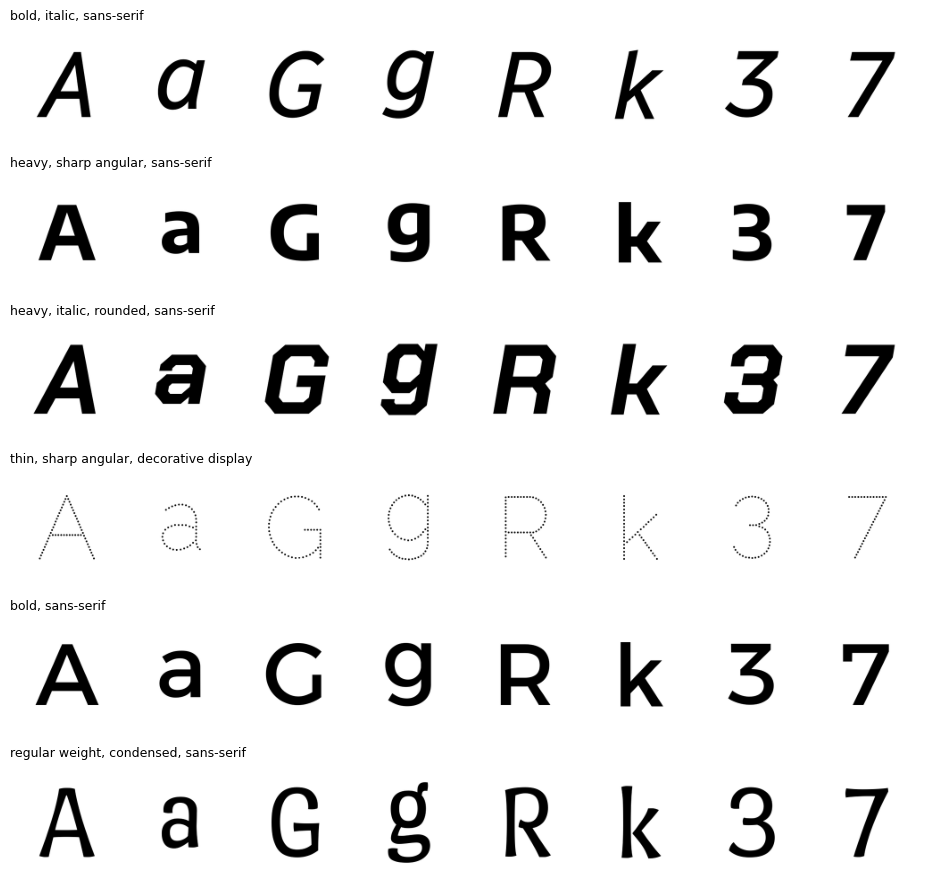

In [10]:
SLANT_CHARS = "HITil"   # characters with vertical stems -> reliable slant estimate
WIDTH_CHARS = "nouah"   # lowercase characters for width estimate

def glyph_geometry(g: np.ndarray) -> np.ndarray:
    strokes, slants, corners, widths = [], [], [], []
    for i, c in enumerate(CHARSET):
        ink = (g[i] < 128).astype(np.uint8)                                  # binary ink mask
        area = int(ink.sum())
        if area < 5:
            continue
        contours, _ = cv2.findContours(ink, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)  # outer + inner outlines
        perim = sum(cv2.arcLength(ct, True) for ct in contours)              # total outline length
        strokes.append(2.0 * area / max(perim, 1.0))                         # stroke width ~ 2*area/perimeter
        pts = cv2.goodFeaturesToTrack(ink.astype(np.float32) * 255, maxCorners=60,
                                      qualityLevel=0.3, minDistance=3)       # sharp corners
        corners.append((0 if pts is None else len(pts)) / max(perim / 100.0, 1e-6))  # corners per 100 px outline
        if c in SLANT_CHARS:
            m = cv2.moments(ink, binaryImage=True)
            if m["mu02"] > 0:
                slants.append(-m["mu11"] / m["mu02"])                        # >0 means leaning right (italic)
        if c in WIDTH_CHARS:
            x, y, w, h = cv2.boundingRect(ink)
            widths.append(w / max(h, 1))                                     # aspect ratio
    return np.array([np.mean(strokes), np.mean(slants) if slants else 0.0,
                     np.mean(corners), np.mean(widths) if widths else 1.0], np.float32)

geo_path = CACHE_DIR / "geometry.npy"                                        # cached features
if geo_path.exists():
    GEOM = np.load(geo_path)
else:
    GEOM = np.stack([glyph_geometry(np.asarray(GLYPHS[f])) for f in tqdm(range(N_FONTS), desc="geometry")])
    np.save(geo_path, GEOM)
    backup_to_drive("geometry.npy")                                          # keep it for later sessions

pct = lambda col, q: np.percentile(GEOM[:, col], q)                          # dataset percentiles
CATEGORY_WORDS = {"SANS_SERIF": "sans-serif", "SERIF": "serif", "DISPLAY": "decorative display",
                  "HANDWRITING": "handwritten", "MONOSPACE": "monospace"}

def describe_font(f: int) -> str:
    stroke, slant, corner, width = GEOM[f]
    words = []
    if stroke < pct(0, 15):   words.append("thin")                          # weight words
    elif stroke < pct(0, 35): words.append("light")
    elif stroke > pct(0, 85): words.append("heavy")
    elif stroke > pct(0, 65): words.append("bold")
    else:                     words.append("regular weight")
    if "italic" in FONTS[f]["path"].lower() or (slant > 0.08 and slant > pct(1, 80)):
        words.append("italic")                                              # slant word
    if corner < pct(2, 30):   words.append("rounded")                       # shape words
    elif corner > pct(2, 70): words.append("sharp angular")
    if width < pct(3, 20):    words.append("condensed")                     # width words
    elif width > pct(3, 80):  words.append("wide")
    cat = CATEGORY_WORDS.get(FONTS[f]["category"])
    if cat:
        words.append(cat)                                                    # category word
    return ", ".join(words)

DESCRIPTIONS = [describe_font(f) for f in range(N_FONTS)]                   # one description per font

fig, axes = plt.subplots(6, 1, figsize=(12, 9))                             # preview a few fonts
for ax, f in zip(axes, random.Random(SEED).sample(range(N_FONTS), 6)):
    strip = np.concatenate([GLYPHS[f, CHAR2IDX[c]] for c in "AaGgRk37"], axis=1)  # glyphs side by side
    ax.imshow(strip, cmap="gray"); ax.axis("off"); ax.set_title(DESCRIPTIONS[f], fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 11. Train / test split by family and datasets

In [11]:
fam_of = [f["family"] for f in FONTS]                                       # family of each font row
uniq_fams = sorted(set(fam_of)); random.Random(SEED).shuffle(uniq_fams)     # random family order
test_fams = set(uniq_fams[:N_TEST_FAMILIES])                                # unseen families -> test
TEST_IDS = [f for f in range(N_FONTS) if fam_of[f] in test_fams]            # no family leakage
TRAIN_IDS = [f for f in range(N_FONTS) if fam_of[f] not in test_fams]
print(f"train fonts {len(TRAIN_IDS)} | test fonts {len(TEST_IDS)}")

class GlyphDataset(Dataset):
    # mode "diffusion" returns cached latents + CLIP embeddings; mode "cvae" returns 128 px pixels
    def __init__(self, font_ids, mode: str):
        self.items = [(f, c) for f in font_ids for c in range(N_CHARS)]    # every (font, char) pair
        self.mode = mode
        self._g = self._l = self._e = None                                  # opened lazily in each worker

    def _open(self):
        if self._g is None:                                                 # memmaps are fork-safe when opened here
            self._g = np.load(GLYPH_PATH, mmap_mode="r")
            self._l = np.load(LATENT_PATH, mmap_mode="r")
            self._e = np.load(CLIPEMB_PATH, mmap_mode="r")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        self._open()
        f, c = self.items[i]
        refs = random.sample([k for k in range(N_CHARS) if k != c], MAX_K)  # MAX_K other chars of the same font
        out = {"font": f, "char": c}
        if self.mode == "diffusion":
            out["latent"] = torch.from_numpy(np.array(self._l[f, c]))                   # target latent
            out["ref_clip"] = torch.from_numpy(np.array(self._e[f, refs]))              # [MAX_K, 768]
            out["ref_img"] = torch.from_numpy(to_ref_res(np.asarray(self._g[f, refs])))  # [MAX_K, 64, 64]
        else:
            out["target"] = torch.from_numpy(np.array(self._g[f, c]))                   # [128, 128]
            out["ref_img"] = torch.from_numpy(np.array(self._g[f, refs]))               # [MAX_K, 128, 128]
        return out

def infinite(loader):
    while True:                 # restart the loader forever (step-based training)
        for b in loader:
            yield b

train fonts 262 | test fonts 38


## 12. StyleEncoder: reference glyphs -> extra cross-attention tokens

In [12]:
def down_block(cin, cout):
    # stride-2 conv halves resolution; GroupNorm is batch-size independent (good for small batches)
    return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), nn.GroupNorm(8, cout), nn.SiLU())

class RefCNN(nn.Module):
    # light CNN for fine stroke details that pooled CLIP embeddings miss
    def __init__(self, out_dim):
        super().__init__()
        self.net = nn.Sequential(down_block(1, 32), down_block(32, 64), down_block(64, 128),
                                 down_block(128, 256))                     # 64 -> 4 px
        self.fc = nn.Linear(256 * 4 * 4, out_dim)                          # flatten -> tokens

    def forward(self, x):
        return self.fc(self.net(x).flatten(1))

class StyleEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.clip_proj = nn.Sequential(nn.Linear(CLIP_DIM, CTX_DIM), nn.SiLU(),
                                       nn.Linear(CTX_DIM, CTX_DIM * N_TOK_CLIP))  # CLIP embedding -> tokens
        self.cnn = RefCNN(CTX_DIM * N_TOK_CNN)                                    # pixels -> tokens
        self.norm = nn.LayerNorm(CTX_DIM)                                         # match text-token scale

    def forward(self, ref_clip, ref_img):
        B, K = ref_clip.shape[:2]                                                 # batch, number of references
        t_clip = self.clip_proj(ref_clip.float()).view(B, K, N_TOK_CLIP, CTX_DIM)
        x = ref_img.float().div(127.5).sub(1.0).view(B * K, 1, REF_RES, REF_RES)  # uint8 -> [-1,1]
        t_cnn = self.cnn(x).view(B, K, N_TOK_CNN, CTX_DIM)
        tokens = torch.cat([t_clip, t_cnn], dim=2).view(B, K * (N_TOK_CLIP + N_TOK_CNN), CTX_DIM)
        return self.norm(tokens)                                                  # [B, K*8, 768]

## 13. Load Stable Diffusion and add LoRA

In [13]:
tokenizer = CLIPTokenizer.from_pretrained(SD_MODEL_ID, subfolder="tokenizer")         # SD tokenizer
text_encoder = load_sd_part(CLIPTextModel, "text_encoder", torch_dtype=WEIGHT_DTYPE)  # half precision
text_encoder = text_encoder.to(DEVICE).eval().requires_grad_(False)                   # frozen
unet = load_sd_part(UNet2DConditionModel, "unet", torch_dtype=WEIGHT_DTYPE)           # half precision UNet
unet = unet.to(DEVICE).requires_grad_(False)                                          # base weights frozen
noise_scheduler = DDPMScheduler.from_pretrained(SD_MODEL_ID, subfolder="scheduler")   # training noise schedule
infer_scheduler = DPMSolverMultistepScheduler.from_pretrained(SD_MODEL_ID, subfolder="scheduler")  # fast sampler

lora_cfg = LoraConfig(r=LORA_RANK, lora_alpha=LORA_RANK, init_lora_weights="gaussian",
                      target_modules=["to_q", "to_k", "to_v", "to_out.0"])  # attention projections only
unet.add_adapter(lora_cfg)                          # inject LoRA layers
cast_training_params(unet, dtype=torch.float32)     # only LoRA params become fp32 (stable optimisation)
unet.enable_gradient_checkpointing()                # recompute activations -> big memory saving

style_enc = StyleEncoder().to(DEVICE)               # trainable, fp32 (small)

n_lora = sum(p.numel() for p in unet.parameters() if p.requires_grad)   # trainable LoRA params
n_style = sum(p.numel() for p in style_enc.parameters())                # trainable StyleEncoder params
print(f"trainable: LoRA {n_lora/1e6:.2f}M + StyleEncoder {n_style/1e6:.2f}M")
gpu_mem("models loaded")

@torch.no_grad()
def encode_text(prompts):
    ids = tokenizer(prompts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(DEVICE)   # token ids [B,77]
    return text_encoder(ids)[0]                                                  # hidden states [B,77,768]

def build_condition(prompts, ref_clip, ref_img, keep):
    txt = encode_text(prompts).to(WEIGHT_DTYPE)                    # text tokens (frozen)
    sty = style_enc(ref_clip, ref_img) * keep.view(-1, 1, 1)       # style tokens, zeroed when refs are dropped
    return torch.cat([txt, sty.to(WEIGHT_DTYPE)], dim=1)           # [B, 77 + K*8, 768]

def sample_conditions(chars, fonts):
    prompts, keep = [], []
    for c, f in zip(chars, fonts):
        r = random.random()
        if r < P_UNCOND:                                           # unconditional (for CFG)
            prompts.append(""); keep.append(0.0)
        elif r < P_UNCOND + P_TEXT_ONLY:                           # text-only
            prompts.append(build_prompt(CHARSET[c], DESCRIPTIONS[f])); keep.append(0.0)
        elif r < P_UNCOND + P_TEXT_ONLY + P_IMAGE_ONLY:            # image-only (char name kept, no style words)
            prompts.append(build_prompt(CHARSET[c])); keep.append(1.0)
        else:                                                      # image + text
            prompts.append(build_prompt(CHARSET[c], DESCRIPTIONS[f])); keep.append(1.0)
    return prompts, torch.tensor(keep)

def min_snr_loss(pred, noise, t):
    snr = compute_snr(noise_scheduler, t)                                      # signal-to-noise per sample
    w = torch.clamp(snr, max=MIN_SNR_GAMMA) / snr                              # Min-SNR-gamma weights (eps-pred)
    mse = F.mse_loss(pred.float(), noise.float(), reduction="none").mean(dim=[1, 2, 3])  # per-sample MSE
    return (mse * w).mean()

def make_optimizer(params, lr):
    try:
        import bitsandbytes as bnb
        return bnb.optim.AdamW8bit(params, lr=lr, weight_decay=1e-2)   # 8-bit states: ~4x less optimizer memory
    except Exception as e:
        print("bitsandbytes unavailable, using torch AdamW:", e)
        return torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


trainable: LoRA 1.59M + StyleEncoder 16.23M
[GPU models loaded] allocated 1.90 GB | reserved 1.91 GB


## 14. Train LangFont (resumable)

no checkpoint found on Drive, starting from step 0


LangFont:   0%|          | 0/4000 [00:00<?, ?it/s]


[saved step 200 to Drive | 104.0 MB]

[saved step 400 to Drive | 104.0 MB]

[saved step 600 to Drive | 104.0 MB]

[saved step 800 to Drive | 104.0 MB]

[saved step 1000 to Drive | 104.0 MB]

[saved step 1200 to Drive | 104.0 MB]

[saved step 1400 to Drive | 104.0 MB]

[saved step 1600 to Drive | 104.0 MB]

[saved step 1800 to Drive | 104.0 MB]

[saved step 2000 to Drive | 104.0 MB]

[saved step 2200 to Drive | 104.0 MB]

[saved step 2400 to Drive | 104.0 MB]

[saved step 2600 to Drive | 104.0 MB]

[saved step 2800 to Drive | 104.0 MB]

[saved step 3000 to Drive | 104.0 MB]

[saved step 3200 to Drive | 104.0 MB]

[saved step 3400 to Drive | 104.0 MB]

[saved step 3600 to Drive | 104.0 MB]

[saved step 3800 to Drive | 104.0 MB]

[saved step 4000 to Drive | 104.0 MB]
full checkpoint: 104.0 MB | final weights: 34.1 MB
[GPU after LangFont training] allocated 1.92 GB | reserved 2.00 GB


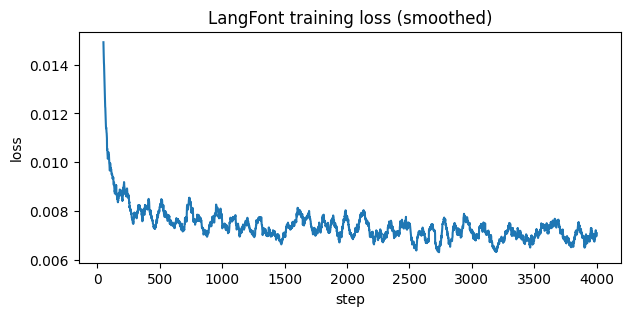

In [14]:
train_ds = GlyphDataset(TRAIN_IDS, "diffusion")            # training pairs
train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0)
trainable = [p for p in unet.parameters() if p.requires_grad] + list(style_enc.parameters())  # what we update
opt = make_optimizer(trainable, LEARNING_RATE)
lr_sched = get_scheduler("cosine", optimizer=opt, num_warmup_steps=LR_WARMUP, num_training_steps=MAX_TRAIN_STEPS)
scaler = torch.amp.GradScaler("cuda", enabled=not USE_BF16)  # loss scaling only needed for fp16

start_step, losses = 0, []
ck = safe_load(CKPT)                                       # look for a checkpoint on Drive (main file, then .bak)
if ck is not None:                                         # resume after the GPU limit / a disconnect
    set_peft_model_state_dict(unet, ck["lora"])            # LoRA weights
    style_enc.load_state_dict(ck["style"])                 # StyleEncoder weights
    try:
        opt.load_state_dict(ck["opt"])                     # optimizer moments (smooth continuation)
    except Exception as e:
        print("optimizer state not restored (optimizer type changed?), continuing with fresh moments:", e)
    lr_sched.load_state_dict(ck["sched"])                  # learning-rate position in the cosine schedule
    scaler.load_state_dict(ck["scaler"])                   # fp16 loss-scale value
    start_step, losses = ck["step"], ck["losses"]          # where to continue
    if "rng" in ck:
        random.setstate(ck["rng"]["py"]); np.random.set_state(ck["rng"]["np"])  # restore random streams
        torch.set_rng_state(ck["rng"]["torch"]); torch.cuda.set_rng_state(ck["rng"]["cuda"])
    del ck; free_memory()
    print(f"resumed from step {start_step} / {MAX_TRAIN_STEPS} (loaded from {CKPT.parent})")
else:
    print("no checkpoint found on Drive, starting from step 0")

def save_ckpt(step):
    state = {"step": step, "res": RES,
             "lora": get_peft_model_state_dict(unet),                       # only LoRA tensors, not the full UNet
             "style": style_enc.state_dict(),
             "opt": opt.state_dict(), "sched": lr_sched.state_dict(), "scaler": scaler.state_dict(),
             "losses": losses,
             "rng": {"py": random.getstate(), "np": np.random.get_state(),
                     "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state()}}
    safe_save(state, CKPT)                                  # temp file -> swap, old one kept as .bak
    print(f"\n[saved step {step} to Drive | {file_mb(CKPT)}]")

def save_final_weights():
    # small inference-only file: LoRA + StyleEncoder in half precision (no optimizer)
    half = lambda sd: {k: v.half() if v.is_floating_point() else v for k, v in sd.items()}
    safe_save({"lora": half(get_peft_model_state_dict(unet)), "style": half(style_enc.state_dict()),
               "res": RES, "lora_rank": LORA_RANK}, FINAL_WEIGHTS)

if start_step < MAX_TRAIN_STEPS:
    unet.train(); style_enc.train()                        # train mode activates gradient checkpointing
    batches = infinite(train_loader)
    last_save = time.time()                                # for time-based saving
    pbar = tqdm(range(start_step, MAX_TRAIN_STEPS), initial=start_step, total=MAX_TRAIN_STEPS, desc="LangFont")
    for step in pbar:
        step_loss = 0.0
        for _ in range(GRAD_ACCUM):                        # gradient accumulation = big batch, small memory
            b = next(batches)
            K = random.choice(K_TRAIN_CHOICES)             # random number of references this micro-batch
            latents = b["latent"].to(DEVICE, non_blocking=True).to(WEIGHT_DTYPE)   # clean latents
            ref_clip = b["ref_clip"][:, :K].to(DEVICE, non_blocking=True)          # first K references
            ref_img = b["ref_img"][:, :K].to(DEVICE, non_blocking=True)
            prompts, keep = sample_conditions(b["char"].tolist(), b["font"].tolist())  # modality dropout
            noise = torch.randn_like(latents)                                       # target noise
            t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],),
                              device=DEVICE).long()                                 # random timesteps
            noisy = noise_scheduler.add_noise(latents, noise, t)                    # forward diffusion
            with torch.autocast("cuda", dtype=WEIGHT_DTYPE):                        # mixed precision
                cond = build_condition(prompts, ref_clip, ref_img, keep.to(DEVICE))
                pred = unet(noisy, t, encoder_hidden_states=cond).sample           # predicted noise
            loss = min_snr_loss(pred, noise, t) / GRAD_ACCUM
            scaler.scale(loss).backward()                                           # accumulate gradients
            step_loss += loss.item()
        scaler.unscale_(opt)                                                        # real gradient values
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)                              # avoid spikes
        scaler.step(opt); scaler.update(); lr_sched.step()                          # update weights and LR
        opt.zero_grad(set_to_none=True)                                             # free gradient memory
        losses.append(step_loss)
        if (step + 1) % LOG_EVERY == 0:
            pbar.set_postfix(loss=f"{np.mean(losses[-LOG_EVERY:]):.4f}",
                             mem=f"{torch.cuda.max_memory_allocated()/1024**3:.1f}GB")
        time_up = (time.time() - last_save) > SAVE_EVERY_MIN * 60                 # minutes since last save
        if (step + 1) % SAVE_EVERY == 0 or time_up or step + 1 == MAX_TRAIN_STEPS:
            save_ckpt(step + 1)                                                     # Drive checkpoint
            last_save = time.time()
    del batches

save_final_weights()                                            # small file for inference / GitHub release
print("full checkpoint:", file_mb(CKPT), "| final weights:", file_mb(FINAL_WEIGHTS))

unet.eval(); style_enc.eval()                                  # inference mode from here on
del opt, lr_sched, scaler, train_loader, train_ds               # drop optimizer states and workers
free_memory(); gpu_mem("after LangFont training")

plt.figure(figsize=(7, 3))                                      # loss curve
plt.plot(pd.Series(losses).rolling(max(1, LOG_EVERY)).mean()); plt.xlabel("step"); plt.ylabel("loss")
plt.title("LangFont training loss (smoothed)"); plt.savefig(PERSIST_DIR / "loss_langfont.png", dpi=120); plt.show()

## 15. CVAE baseline (thesis-style few-shot model)
Encoder q(z | target, style, char), decoder p(target | z, style, char). Style = mean of K reference encodings,
so the same model works for any K. Set `CVAE_CHECKPOINT` to reuse your thesis weights if the architecture matches.

In [15]:
def up_block(cin, cout):
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.GroupNorm(8, cout), nn.SiLU())  # x2 upsample

def conv_tower():
    # 128 -> 4 px feature map, flattened to 4096
    return nn.Sequential(down_block(1, 32), down_block(32, 64), down_block(64, 128),
                         down_block(128, 256), down_block(256, 256), nn.Flatten())

class FewShotCVAE(nn.Module):
    def __init__(self, z_dim=CVAE_Z, style_dim=256, char_dim=64):
        super().__init__()
        self.ref_enc = nn.Sequential(conv_tower(), nn.Linear(4096, style_dim))  # one reference -> style vector
        self.char_emb = nn.Embedding(N_CHARS, char_dim)                         # content = which character
        self.tgt_enc = conv_tower()                                              # target glyph encoder
        self.to_stats = nn.Linear(4096 + style_dim + char_dim, 2 * z_dim)        # mu and log-variance
        self.dec_in = nn.Linear(z_dim + style_dim + char_dim, 256 * 4 * 4)       # decoder seed
        self.dec = nn.Sequential(up_block(256, 256), up_block(256, 128), up_block(128, 64),
                                 up_block(64, 32), nn.ConvTranspose2d(32, 1, 4, 2, 1))  # 4 -> 128 px logits
        self.z_dim = z_dim

    @staticmethod
    def ink(x):
        return 1.0 - x.float() / 255.0                         # uint8 white-bg glyph -> ink map (1 = ink)

    def style(self, refs):
        B, K = refs.shape[:2]
        s = self.ref_enc(self.ink(refs).view(B * K, 1, CVAE_RES, CVAE_RES))     # encode each reference
        return s.view(B, K, -1).mean(1)                                          # average -> any K works

    def decode(self, z, s, ce):
        return self.dec(self.dec_in(torch.cat([z, s, ce], 1)).view(-1, 256, 4, 4))  # logits [B,1,128,128]

    def forward(self, target, refs, chars):
        s, ce = self.style(refs), self.char_emb(chars)
        mu, logvar = self.to_stats(torch.cat([self.tgt_enc(self.ink(target).unsqueeze(1)), s, ce], 1)).chunk(2, 1)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)                  # reparameterisation trick
        return self.decode(z, s, ce), mu, logvar

    @torch.no_grad()
    def generate(self, refs, chars):
        s, ce = self.style(refs), self.char_emb(chars)
        z = torch.zeros(len(chars), self.z_dim, device=refs.device)              # mean latent = cleanest output
        p = torch.sigmoid(self.decode(z, s, ce).float())[:, 0]                   # ink probability
        return (255 * (1 - p)).round().byte()                                    # back to white-bg uint8

cvae = FewShotCVAE().to(DEVICE)
loaded = False
if CVAE_CHECKPOINT and Path(CVAE_CHECKPOINT).exists():          # optional: your thesis weights
    try:
        cvae.load_state_dict(torch.load(CVAE_CHECKPOINT, map_location="cpu")); loaded = True
        print("loaded thesis CVAE weights")
    except Exception as e:
        print("thesis weights do not match this architecture, training instead:", e)

if not loaded:
    c_opt = torch.optim.AdamW(cvae.parameters(), lr=CVAE_LR, weight_decay=1e-4)
    c_scaler = torch.amp.GradScaler("cuda", enabled=not USE_BF16)
    c_start, c_losses = 0, []
    ck = safe_load(CVAE_CKPT)                                    # resume from Drive if a save exists
    if ck is not None:
        cvae.load_state_dict(ck["model"]); c_opt.load_state_dict(ck["opt"])
        if "scaler" in ck:
            c_scaler.load_state_dict(ck["scaler"])
        c_start, c_losses = ck["step"], ck["losses"]
        del ck
        print(f"CVAE resumed from step {c_start} / {CVAE_STEPS}")
    if c_start < CVAE_STEPS:
        c_loader = DataLoader(GlyphDataset(TRAIN_IDS, "cvae"), batch_size=CVAE_BATCH, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
        c_batches = infinite(c_loader); cvae.train()
        c_last_save = time.time()                                # for time-based saving
        for step in tqdm(range(c_start, CVAE_STEPS), initial=c_start, total=CVAE_STEPS, desc="CVAE"):
            b = next(c_batches)
            K = random.choice(K_TRAIN_CHOICES)                                     # random K, like LangFont
            tgt = b["target"].to(DEVICE, non_blocking=True)
            refs = b["ref_img"][:, :K].to(DEVICE, non_blocking=True)
            chars = b["char"].to(DEVICE)
            with torch.autocast("cuda", dtype=WEIGHT_DTYPE):
                logits, mu, logvar = cvae(tgt, refs, chars)
            rec = F.binary_cross_entropy_with_logits(logits.float()[:, 0], cvae.ink(tgt), reduction="sum") / len(tgt)
            kl = -0.5 * torch.sum(1 + logvar.float() - mu.float() ** 2 - logvar.float().exp()) / len(tgt)
            beta = CVAE_BETA * min(1.0, (step + 1) / CVAE_KL_WARMUP)               # KL annealing
            loss = rec + beta * kl
            c_opt.zero_grad(set_to_none=True)
            c_scaler.scale(loss).backward(); c_scaler.step(c_opt); c_scaler.update()
            c_losses.append(loss.item())
            time_up = (time.time() - c_last_save) > SAVE_EVERY_MIN * 60
            if (step + 1) % (SAVE_EVERY * 2) == 0 or time_up or step + 1 == CVAE_STEPS:
                safe_save({"step": step + 1, "model": cvae.state_dict(), "opt": c_opt.state_dict(),
                           "scaler": c_scaler.state_dict(), "losses": c_losses}, CVAE_CKPT)  # Drive checkpoint
                c_last_save = time.time()
        del c_batches, c_loader
    del c_opt, c_scaler
    safe_save(cvae.state_dict(), CVAE_FINAL)                     # weights-only file
    print("CVAE checkpoint:", file_mb(CVAE_CKPT), "| CVAE weights:", file_mb(CVAE_FINAL))
cvae.eval(); free_memory(); gpu_mem("after CVAE")

CVAE:   0%|          | 0/6000 [00:00<?, ?it/s]

CVAE checkpoint: 105.9 MB | CVAE weights: 35.3 MB
[GPU after CVAE] allocated 1.99 GB | reserved 2.18 GB


## 16. Inference functions

In [16]:
vae = load_vae()                                            # needed again for decoding

@torch.inference_mode()
def diffuse(prompts, ref_clip, ref_img, keep, steps=INFER_STEPS, guidance=GUIDANCE, seed=SEED):
    B = len(prompts)
    with torch.autocast("cuda", dtype=WEIGHT_DTYPE):
        cond = build_condition(prompts, ref_clip, ref_img, keep)                           # conditional context
        uncond = build_condition([""] * B, ref_clip, ref_img, torch.zeros_like(keep))       # empty context
    context = torch.cat([uncond, cond]).to(WEIGHT_DTYPE)                                    # one batched UNet call
    gen = torch.Generator(device=DEVICE).manual_seed(seed)                                  # same noise across methods
    latents = torch.randn((B, 4, RES // 8, RES // 8), generator=gen, device=DEVICE, dtype=WEIGHT_DTYPE)
    infer_scheduler.set_timesteps(steps, device=DEVICE)
    latents = latents * infer_scheduler.init_noise_sigma
    for t in infer_scheduler.timesteps:
        x_in = infer_scheduler.scale_model_input(torch.cat([latents] * 2), t)
        with torch.autocast("cuda", dtype=WEIGHT_DTYPE):
            eps = unet(x_in, t, encoder_hidden_states=context).sample
        eps_u, eps_c = eps.chunk(2)
        eps = eps_u + guidance * (eps_c - eps_u)                                             # classifier-free guidance
        latents = infer_scheduler.step(eps, t, latents).prev_sample.to(WEIGHT_DTYPE)
    return vae_decode(vae, latents)                                                          # uint8 [B,RES,RES]

def langfont_generate(fonts, chars, ref_lists, K, mode):
    out = []
    for s in range(0, len(fonts), GEN_BATCH):                                # small chunks = bounded memory
        fs, cs, rs = fonts[s:s + GEN_BATCH], chars[s:s + GEN_BATCH], ref_lists[s:s + GEN_BATCH]
        ref_clip = torch.from_numpy(np.stack([np.asarray(CLIPEMB[f, r[:K]]) for f, r in zip(fs, rs)])).to(DEVICE)
        ref_img = torch.from_numpy(np.stack([to_ref_res(np.asarray(GLYPHS[f, r[:K]])) for f, r in zip(fs, rs)])).to(DEVICE)
        style = (lambda f: None) if mode == "image_only" else (lambda f: DESCRIPTIONS[f])   # drop words for image-only
        prompts = [build_prompt(CHARSET[c], style(f)) for f, c in zip(fs, cs)]
        keep = torch.full((len(fs),), 0.0 if mode == "text_only" else 1.0, device=DEVICE)  # drop refs for text-only
        imgs = diffuse(prompts, ref_clip, ref_img, keep, seed=SEED + s)
        out.append(resize_stack(imgs, EVAL_RES))
    return np.concatenate(out)

def cvae_generate(fonts, chars, ref_lists, K):
    out = []
    for s in range(0, len(fonts), 64):
        fs, cs, rs = fonts[s:s + 64], chars[s:s + 64], ref_lists[s:s + 64]
        refs = torch.from_numpy(np.stack([np.asarray(GLYPHS[f, r[:K]]) for f, r in zip(fs, rs)])).to(DEVICE)
        with torch.autocast("cuda", dtype=WEIGHT_DTYPE):
            imgs = cvae.generate(refs, torch.tensor(cs, device=DEVICE)).cpu().numpy()
        out.append(resize_stack(imgs, EVAL_RES))
    return np.concatenate(out)

## 17. Evaluation set and generation for every ablation
Each test font gets fixed target characters and a fixed ordered list of 10 references.
K = 1/3/5/10 uses the first K of that list, so the ablation is nested and fair.

In [17]:
EVAL_FONTS, EVAL_CHARS, EVAL_REFS = [], [], []
targets = [CHAR2IDX[c] for c in TARGET_CHARS[:N_TARGETS_PER_FONT]]       # same targets for all fonts
for f in TEST_IDS:
    r = random.Random(SEED + f).sample([k for k in range(N_CHARS) if k not in targets], MAX_K)  # fixed refs
    for c in targets:
        EVAL_FONTS.append(f); EVAL_CHARS.append(c); EVAL_REFS.append(r)
GT = np.stack([resize_stack(np.asarray(GLYPHS[f, c])[None], EVAL_RES)[0] for f, c in zip(EVAL_FONTS, EVAL_CHARS)])
print(f"evaluation images per method: {len(GT)}")

CONFIGS = ([("LangFont", "both", K) for K in K_EVAL] +
           [("LangFont", "image_only", K_MODALITY), ("LangFont", "text_only", K_MODALITY)] +
           [("CVAE", "image_only", K) for K in K_EVAL])                  # (method, modality, K)

GEN_DIR.mkdir(exist_ok=True)   # generations live on Drive, so finished configs are skipped after a restart
GENS = {}
for method, mode, K in CONFIGS:
    key = f"{method}_{mode}_K{K}"
    path = GEN_DIR / f"{key}.npy"
    if path.exists():
        GENS[key] = np.load(path); continue                             # skip work already done
    t0 = time.time()
    if method == "LangFont":
        GENS[key] = langfont_generate(EVAL_FONTS, EVAL_CHARS, EVAL_REFS, K, mode)
    else:
        GENS[key] = cvae_generate(EVAL_FONTS, EVAL_CHARS, EVAL_REFS, K)
    np.save(path, GENS[key])
    print(f"{key}: {time.time()-t0:.0f}s")
free_memory(); gpu_mem("after generation")

evaluation images per method: 380
LangFont_both_K1: 348s
LangFont_both_K3: 347s
LangFont_both_K5: 349s
LangFont_both_K10: 355s
LangFont_image_only_K5: 349s
LangFont_text_only_K5: 348s
CVAE_image_only_K1: 0s
CVAE_image_only_K3: 0s
CVAE_image_only_K5: 0s
CVAE_image_only_K10: 1s
[GPU after generation] allocated 2.15 GB | reserved 2.18 GB


## 18. Metrics: FID, KID, SSIM, CLIP-T, CLIP-I

In [18]:
def to_inception(batch_uint8):
    x = torch.from_numpy(batch_uint8).to(DEVICE).float().div(255.0)   # [B,H,W] in [0,1]
    return x.unsqueeze(1).repeat(1, 3, 1, 1)                          # 3-channel float for Inception

clip_vis = load_clip_vision()                                          # image tower
clip_tok = CLIPTokenizer.from_pretrained(CLIP_MODEL_ID)                # text tokenizer
clip_txt = CLIPTextModelWithProjection.from_pretrained(CLIP_MODEL_ID, torch_dtype=WEIGHT_DTYPE).to(DEVICE).eval()

@torch.inference_mode()
def clip_text_embed(prompts, bs=64):
    outs = []
    for s in range(0, len(prompts), bs):
        ids = clip_tok(prompts[s:s + bs], padding=True, truncation=True, return_tensors="pt").to(DEVICE)
        outs.append(F.normalize(clip_txt(**ids).text_embeds.float(), dim=-1))
    return torch.cat(outs)

full_prompts = [build_prompt(CHARSET[c], DESCRIPTIONS[f]) for f, c in zip(EVAL_FONTS, EVAL_CHARS)]  # intended target
TXT_E = clip_text_embed(full_prompts)                                  # text embeddings
GT_E = clip_image_embed(clip_vis, GT)                                  # ground-truth image embeddings

n = len(GT)
fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(DEVICE)
kid = KernelInceptionDistance(subset_size=min(50, n), normalize=True, reset_real_features=False).to(DEVICE)
for s in range(0, n, 64):                                              # real statistics computed once
    x = to_inception(GT[s:s + 64]); fid.update(x, real=True); kid.update(x, real=True)

rows = []
for method, mode, K in CONFIGS:
    key = f"{method}_{mode}_K{K}"; gen = GENS[key]
    fid.reset(); kid.reset()                                           # keeps real features
    for s in range(0, n, 64):
        x = to_inception(gen[s:s + 64]); fid.update(x, real=False); kid.update(x, real=False)
    kid_mean, _ = kid.compute()
    gen_e = clip_image_embed(clip_vis, gen)
    rows.append({
        "Method": method, "Modality": mode.replace("_", " ") if method == "LangFont" else "images (baseline)", "K": K,
        "FID ↓": float(fid.compute()),
        "KID×1000 ↓": float(kid_mean) * 1000,
        "SSIM ↑": float(np.mean([structural_similarity(a, b, data_range=255) for a, b in zip(GT, gen)])),
        "CLIP-T ↑": float((100 * (gen_e * TXT_E).sum(-1).clamp(min=0)).mean()),   # text-image alignment
        "CLIP-I ↑": float((gen_e * GT_E).sum(-1).mean()),                          # similarity to true glyph
    })

RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(PERSIST_DIR / "results.csv", index=False)                  # save for the paper / portfolio
del clip_vis, clip_txt, fid, kid; free_memory()
RESULTS.round(3)

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.embeddings.position_embedding.weight              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.weight        | UNEXPECTED |  | 
vision_

,Method,Modality,K,FID ↓,KID×1000 ↓,SSIM ↑,CLIP-T ↑,CLIP-I ↑
0,LangFont,both,1,51.054,8.558,0.736,28.746,0.871
1,LangFont,both,3,54.399,8.334,0.734,28.841,0.875
2,LangFont,both,5,54.073,7.800,0.734,28.808,0.877
3,LangFont,both,10,52.322,7.978,0.742,28.662,0.880
4,LangFont,image only,5,54.070,7.651,0.746,28.973,0.879
5,LangFont,text only,5,73.747,15.755,0.645,28.559,0.844
6,CVAE,images (baseline),1,185.463,93.951,0.818,26.154,0.773
7,CVAE,images (baseline),3,183.856,90.348,0.818,26.202,0.776
8,CVAE,images (baseline),5,184.618,94.271,0.818,26.191,0.776
9,CVAE,images (baseline),10,184.856,94.655,0.818,26.221,0.777


## 19. Ablation plots and qualitative comparison

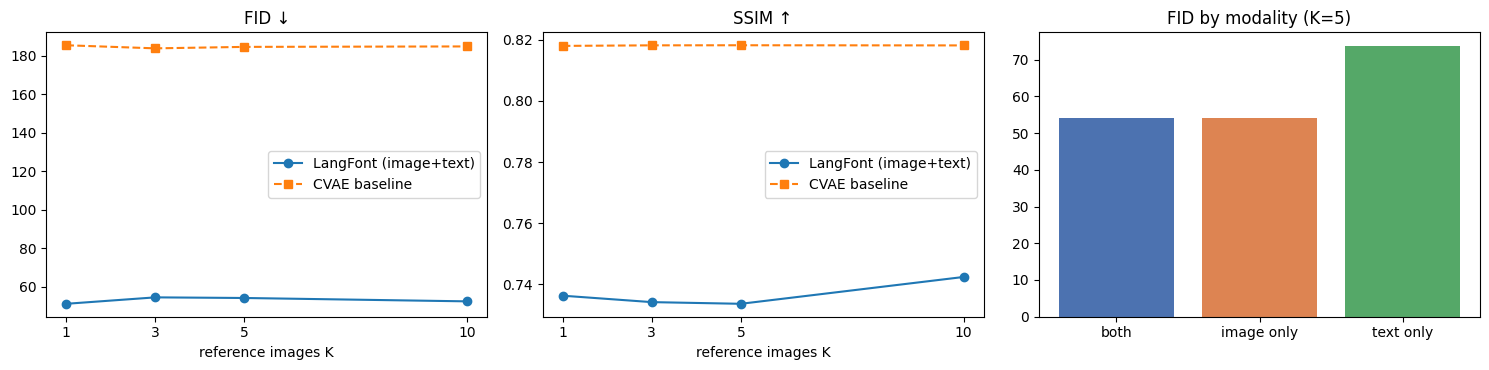

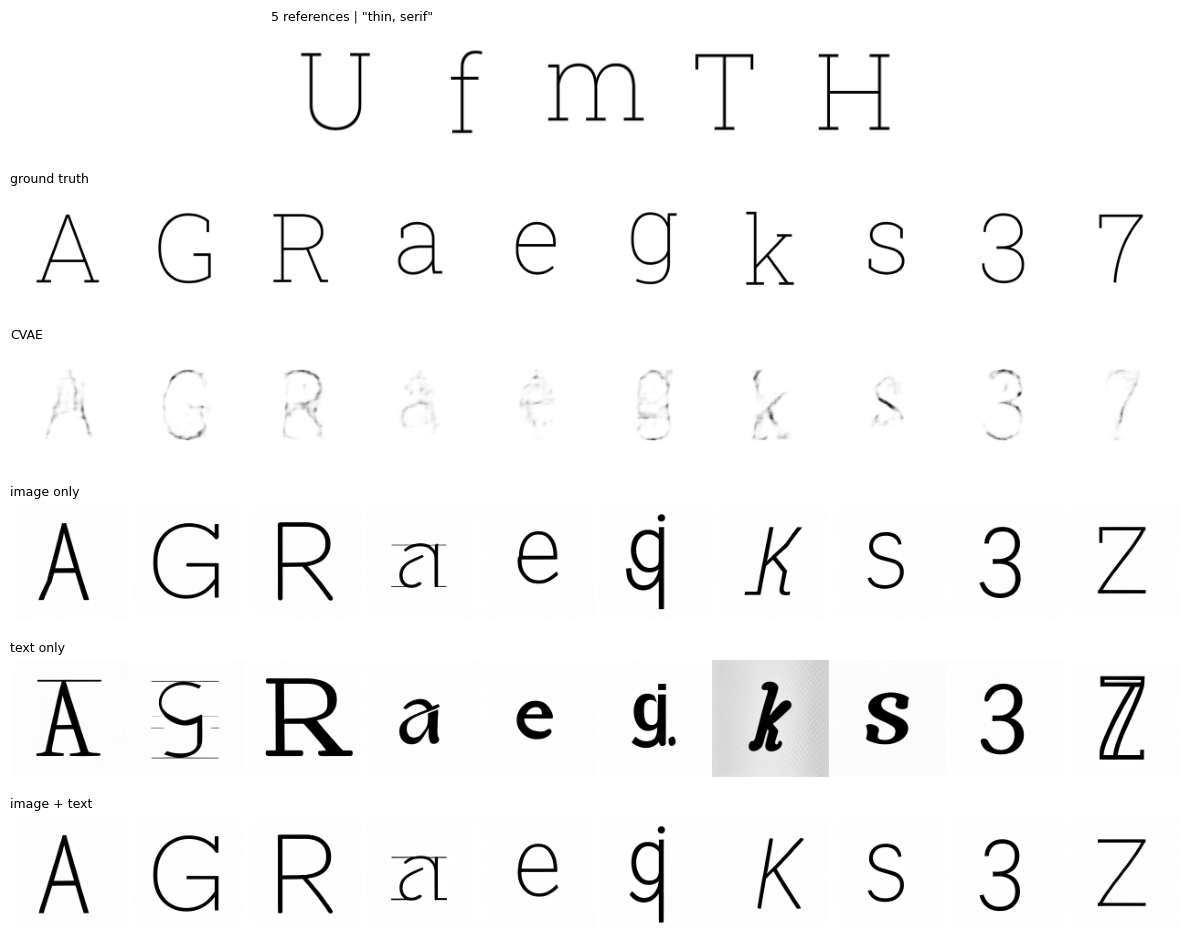

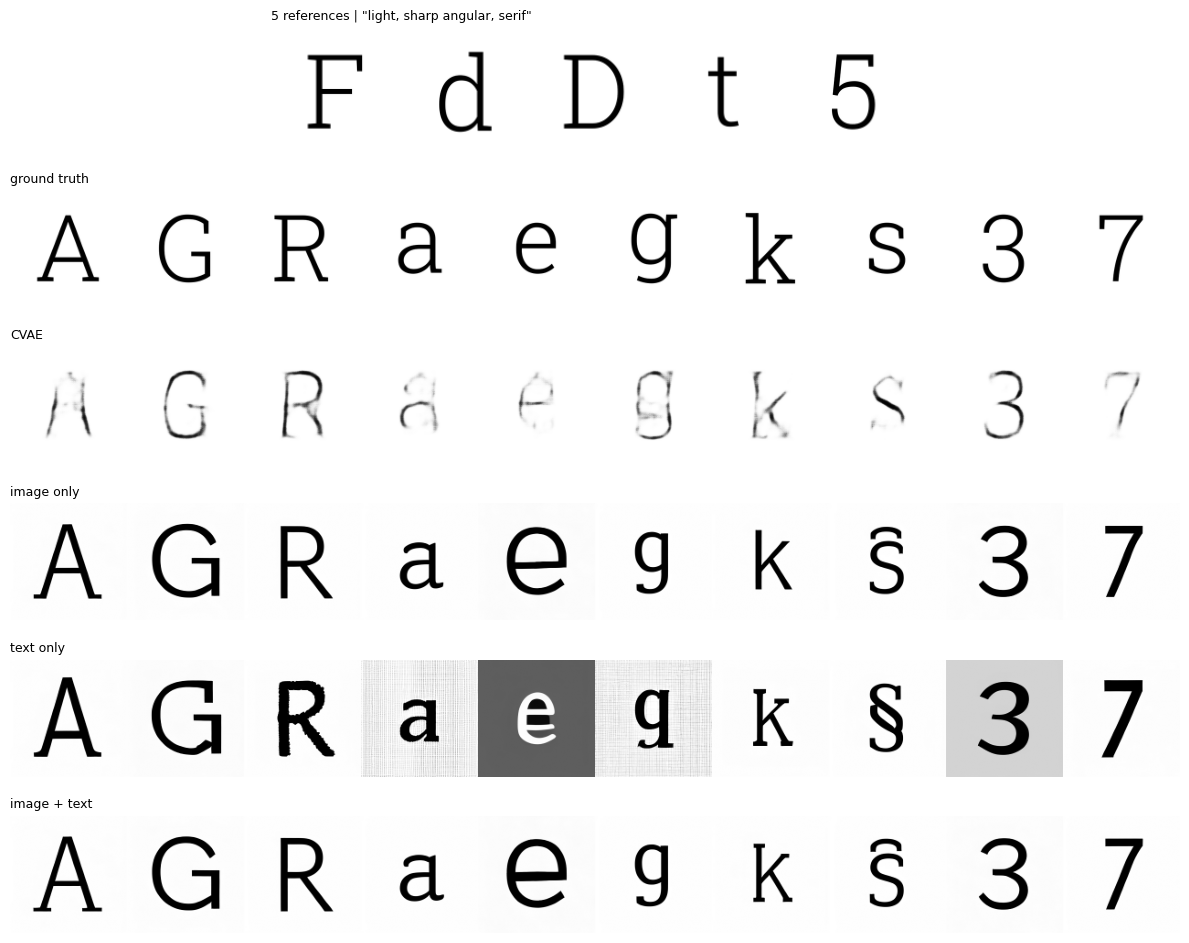

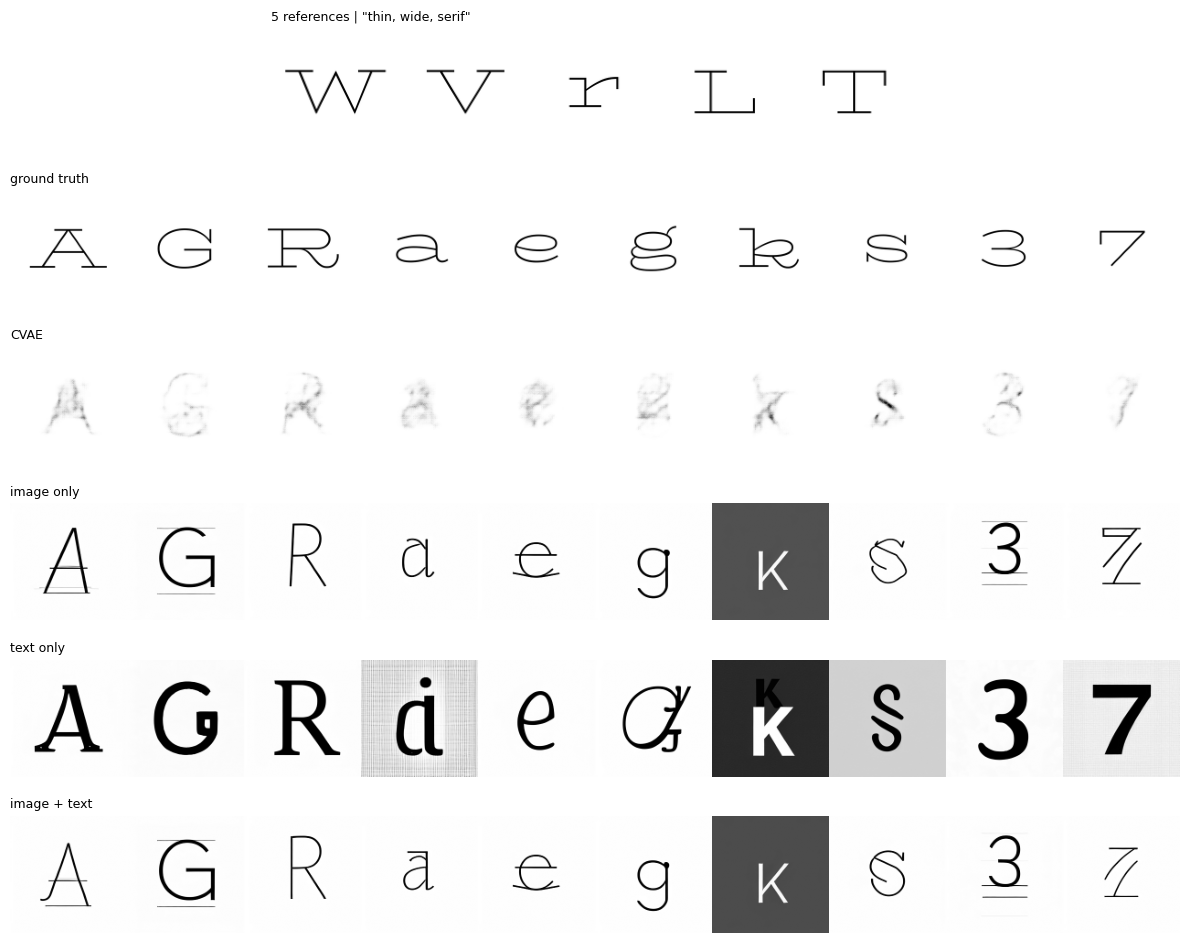

In [19]:
lf = RESULTS[(RESULTS.Method == "LangFont") & (RESULTS.Modality == "both")]   # LangFont K curve
cv = RESULTS[RESULTS.Method == "CVAE"]                                       # CVAE K curve
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, m in zip(ax[:2], ["FID ↓", "SSIM ↑"]):
    a.plot(lf.K, lf[m], "o-", label="LangFont (image+text)"); a.plot(cv.K, cv[m], "s--", label="CVAE baseline")
    a.set_xlabel("reference images K"); a.set_title(m); a.set_xticks(K_EVAL); a.legend()
mod = RESULTS[(RESULTS.Method == "LangFont") & (RESULTS.K == K_MODALITY)]    # modality ablation at K=5
ax[2].bar(mod.Modality, mod["FID ↓"], color=["#4c72b0", "#dd8452", "#55a868"][:len(mod)])
ax[2].set_title(f"FID by modality (K={K_MODALITY})")
plt.tight_layout(); plt.savefig(PERSIST_DIR / "ablations.png", dpi=150); plt.show()

def show_font(slot: int):
    sl = slice(slot * N_TARGETS_PER_FONT, (slot + 1) * N_TARGETS_PER_FONT)   # rows of this font
    f = EVAL_FONTS[sl.start]
    refs = np.concatenate([GLYPHS[f, r] for r in EVAL_REFS[sl.start][:K_MODALITY]], axis=1)
    rows_ = [("ground truth", GT[sl]), ("CVAE", GENS[f"CVAE_image_only_K{K_MODALITY}"][sl]),
             ("image only", GENS[f"LangFont_image_only_K{K_MODALITY}"][sl]),
             ("text only", GENS[f"LangFont_text_only_K{K_MODALITY}"][sl]),
             ("image + text", GENS[f"LangFont_both_K{K_MODALITY}"][sl])]
    fig, ax = plt.subplots(len(rows_) + 1, 1, figsize=(12, 1.6 * (len(rows_) + 1)))
    ax[0].imshow(refs, cmap="gray"); ax[0].set_title(f"{K_MODALITY} references | \"{DESCRIPTIONS[f]}\"", loc="left", fontsize=9)
    for a, (name, imgs) in zip(ax[1:], rows_):
        a.imshow(np.concatenate(list(imgs), axis=1), cmap="gray"); a.set_title(name, loc="left", fontsize=9)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

for slot in range(min(3, len(TEST_IDS))):   # a few unseen fonts
    show_font(slot)

## 20. Demo: your own reference images + any text prompt
Put 1-10 glyph images (PNG/JPG, one character each) in `USER_REF_DIR`. Without a folder, the demo uses a test
font and shows how **changing only the text** changes the output.

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.embeddings.position_embedding.weight              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{

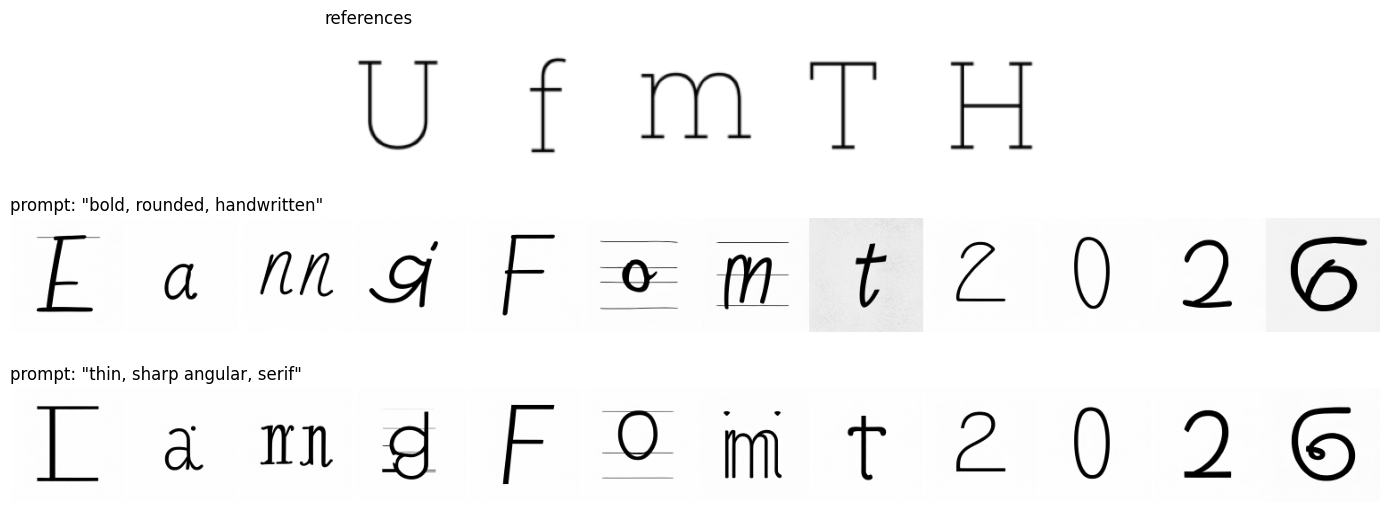

In [20]:
USER_REF_DIR = PERSIST_DIR / "my_refs"         # your reference glyph images (Drive: MyDrive/LangFont/my_refs)
DEMO_CHARS = "LangFont2026"                    # characters to generate
DEMO_STYLES = ["bold, rounded, handwritten", "thin, sharp angular, serif"]  # text prompts to try

def preprocess_user_glyph(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)                              # read as grayscale
    _, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)       # clean binarisation
    if (bw < 128).mean() > 0.5:
        bw = 255 - bw                                                              # ensure black ink on white
    ys, xs = np.where(bw < 128)
    crop = bw[ys.min():ys.max() + 1, xs.min():xs.max() + 1]                        # tight crop
    s = 0.8 * RES / max(crop.shape)
    crop = cv2.resize(crop, (max(1, int(crop.shape[1] * s)), max(1, int(crop.shape[0] * s))), interpolation=cv2.INTER_AREA)
    canvas = np.full((RES, RES), 255, np.uint8)                                    # centre on canvas
    y0, x0 = (RES - crop.shape[0]) // 2, (RES - crop.shape[1]) // 2
    canvas[y0:y0 + crop.shape[0], x0:x0 + crop.shape[1]] = crop
    return canvas

if USER_REF_DIR.exists() and any(USER_REF_DIR.iterdir()):
    files = sorted(p for p in USER_REF_DIR.iterdir() if p.suffix.lower() in (".png", ".jpg", ".jpeg"))[:MAX_K]
    refs_hr = np.stack([preprocess_user_glyph(p) for p in files])                 # [K, RES, RES]
else:
    f0 = TEST_IDS[0]                                                               # fallback: unseen test font
    refs_hr = np.stack([cv2.resize(np.asarray(GLYPHS[f0, r]), (RES, RES)) for r in EVAL_REFS[0][:K_MODALITY]])

clip_vis = load_clip_vision()
demo_clip = clip_image_embed(clip_vis, refs_hr)                                    # [K,768]
del clip_vis; free_memory()
demo_small = torch.from_numpy(resize_stack(refs_hr, REF_RES)).to(DEVICE)          # [K,64,64]

fig, ax = plt.subplots(len(DEMO_STYLES) + 1, 1, figsize=(14, 1.8 * (len(DEMO_STYLES) + 1)))
ax[0].imshow(np.concatenate(list(resize_stack(refs_hr, EVAL_RES)), axis=1), cmap="gray"); ax[0].set_title("references", loc="left")
for a, style in zip(ax[1:], DEMO_STYLES):
    imgs = []
    for s in range(0, len(DEMO_CHARS), GEN_BATCH):
        cs = DEMO_CHARS[s:s + GEN_BATCH]
        B = len(cs)
        imgs.append(diffuse([build_prompt(c, style) for c in cs],
                            demo_clip.unsqueeze(0).expand(B, -1, -1), demo_small.unsqueeze(0).expand(B, -1, -1, -1),
                            torch.ones(B, device=DEVICE), seed=SEED + s))
    a.imshow(np.concatenate(list(resize_stack(np.concatenate(imgs), EVAL_RES)), axis=1), cmap="gray")
    a.set_title(f'prompt: "{style}"', loc="left")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()